# Computer-Aided Drug Design: An Overview
## PHS 312 - Drug Discovery, Design, and Development
### **Lecture 22** · Friday, October 23, 2026 · *50 minutes*

---

**Pre-class reading:** Patrick 7e, Chapter 17 opening and Sections 17.1–17.7

> ⏱️ **Duration:** This activity takes 30-35 minutes.  
> 👥 **Format:** Work in pairs.  
> 🚦 **Instructions:** Run each cell with the play button on its left, answer the question that follows, and keep going. *You will not write any code.*

Markdown Cell 0: Colab Environment Setup
Background:

Computer-Aided Drug Design (CADD) workflows require specialized toolkits for structure parsing, 3D coordinate generation, energy calculations, and interactive visualization. In this environment, we use:

RDKit: An open-source cheminformatics toolkit used for handling chemical structures, SMILES parsing, 3D conformer generation, and MMFF94 force field calculations.

py3Dmol: An open-source, WebGL-based molecular graphics library used to render 3D chemical structures, molecular overlays, and electrostatics natively within Jupyter notebooks.

In [36]:
#@title Set-up  -  run this cell first { display-mode:

### Learning Objectives
By the end of this activity, you should be able to:

| # | Objective | Bloom Level | Syllabus Level | SILO |
|---|---|---|---|---|
| **1** | Identify the five force-field terms and classify each as bonded or non-bonded. | Remember | VI | 6 |
| **2** | Explain why a 3D model is energy-minimized and what the resulting minimum does and does not represent. | Understand | V | 6 |
| **3** | Distinguish molecular mechanics from quantum mechanics by their assumptions, cost, and output. | Analyze | III | 6 |
| **4** | Select molecular mechanics, semi-empirical, or ab initio methods for a stated molecule and question. | Apply | IV | 6 |

*Syllabus levels follow the PHS 312 legend, in which Level I is Creating and Level VI is Remembering.*

Part 1 - What do you already know?
Three questions before you begin. You will not be told whether you are right, and that is deliberate: the point is to measure what you knew coming in, so that at the end you can see how much the activity moved you. Answer from what you remember from the reading. Guessing is fine.

In [33]:
#@title P1   (run after choosing) { display-mode: "form" }
#@markdown **P1.**  A force field calculates the steric energy of a conformation. What does that number let you compare?
#@markdown ---
response = "A. Two conformations of the same molecule, on one energy scale" #@param ["-- choose --", "A. Two conformations of the same molecule, on one energy scale", "B. Two different molecules, giving their relative binding affinity", "C. Two different molecules, giving their relative heat of formation", "D. Two solvents, giving the preferred medium for the reaction"]
gb.answer("P1", response[:1])

[Mock Gradebook] Recorded answer for P1: A


In [25]:
#@title P2   (run after choosing) { display-mode: "form" }
#@markdown **P2.**  Energy minimization is run on a 3D model. Where does the calculation stop?
#@markdown ---
response = "A. At the lowest-energy conformation the molecule can adopt at all" #@param ["-- choose --", "A. At the lowest-energy conformation the molecule can adopt at all", "B. At the conformation observed in the small-molecule crystal form", "C. At the conformation the molecule adopts when bound to its target", "D. At the nearest shape from which every change raises the energy"]
gb.answer("P2", response[:1])

[Mock Gradebook] Recorded answer for P2: A


In [26]:

#@title P3   (run after choosing) { display-mode: "form" }
#@markdown **P3.**  Which property requires a method that computes the distribution of electrons?
#@markdown ---
response = "A. The electrostatic potential map used to locate binding regions" #@param ["-- choose --", "A. The electrostatic potential map used to locate binding regions", "B. The number of rotatable bonds available in a long flexible chain", "C. The steric energy gap between two chair conformations of a ring", "D. The root mean square deviation between two overlaid analogues"]
gb.answer("P3", response[:1])


[Mock Gradebook] Recorded answer for P3: A


In [1]:
# Install RDKit and py3Dmol for molecular modeling and 3D visualization
!pip install -q rdkit py3Dmol

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 20.8 MB/s eta 0:00:00


Markdown Cell 1: 2D SMILES Parsing and 3D Conformer Generation
Background:

Chemical structures are frequently stored in 2D formats such as SMILES (Simplified Molecular-Input Line-Entry System). SMILES strings record atomic connectivity and stereochemistry, but lack explicit 3D spatial coordinates.

To transition from 2D to 3D:

Add Explicit Hydrogens: Hydrogens are often implicit in 2D SMILES representations. Explicit hydrogen atoms are strictly required to define accurate valence angles, torsions, and steric bulk.

Distance Geometry Embedding: The ETKDG (Experimental-Torsion-Distance Geometry with Additional Constraints) algorithm utilizes experimental crystal structure torsional preferences to generate physically realistic 3D atomic coordinates.

In [51]:
from rdkit import Chem
from rdkit.Chem import AllChem

# Define molecule via SMILES string: Acetylsalicylic acid (Aspirin)
smiles = "CC(=O)OC1=CC=CC=C1C(=O)O"
mol_2d = Chem.MolFromSmiles(smiles)

# Add explicit hydrogens required for accurate 3D geometry and force fields
mol_3d = Chem.AddHs(mol_2d)

# Embed 3D coordinates using Distance Geometry (ETKDG method)
AllChem.EmbedMolecule(mol_3d, AllChem.ETKDGv3())

# Preserve an unminimized copy for structural and energy comparison
mol_unminimized = Chem.Mol(mol_3d)

print(f"Molecule: {Chem.MolToSmiles(mol_2d)}")
print(f"Total atoms (with hydrogens): {mol_3d.GetNumAtoms()}")
print(f"3D Conformers generated: {mol_3d.GetNumConformers()}")

Molecule: CC(=O)Oc1ccccc1C(=O)O
Total atoms (with hydrogens): 21
3D Conformers generated: 1


Part 2 - The five force-field terms
A force field adds up a small number of energy terms. Three describe bonded geometry (stretching, bending, torsion) and two describe non-bonded contact through space (van der Waals, Coulombic).

Each panel below plots one term over its own coordinate. Change a parameter, press play, and watch which panel moves. Work out why before you read the numbers underneath.

Markdown Cell 2: MMFF94 Force Field Energy Calculation and Geometry MinimizationBackground:Molecular Mechanics (MM) represents a molecule using a classical "ball-and-spring" physical model. The potential energy of a molecule is governed by an empirical Force Field function, such as MMFF94 (Merck Molecular Force Field).The total steric potential energy $E_{\text{steric}}$ is calculated as the sum of bonded and non-bonded empirical potential energy terms:$$E_{\text{steric}} = E_{\text{stretch}} + E_{\text{bend}} + E_{\text{torsion}} + E_{\text{van der Waals}} + E_{\text{electrostatic}}$$Unminimized 3D structures generated from distance geometry often contain high-energy atomic overlaps (steric clashes) or unfavorable bond angles. Geometry Optimization iteratively adjusts atomic coordinates along the local energy gradient until the forces on all atoms approach zero, settling the molecule into a local potential energy minimum.

/tmp/ipykernel_532/1814332356.py:108: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


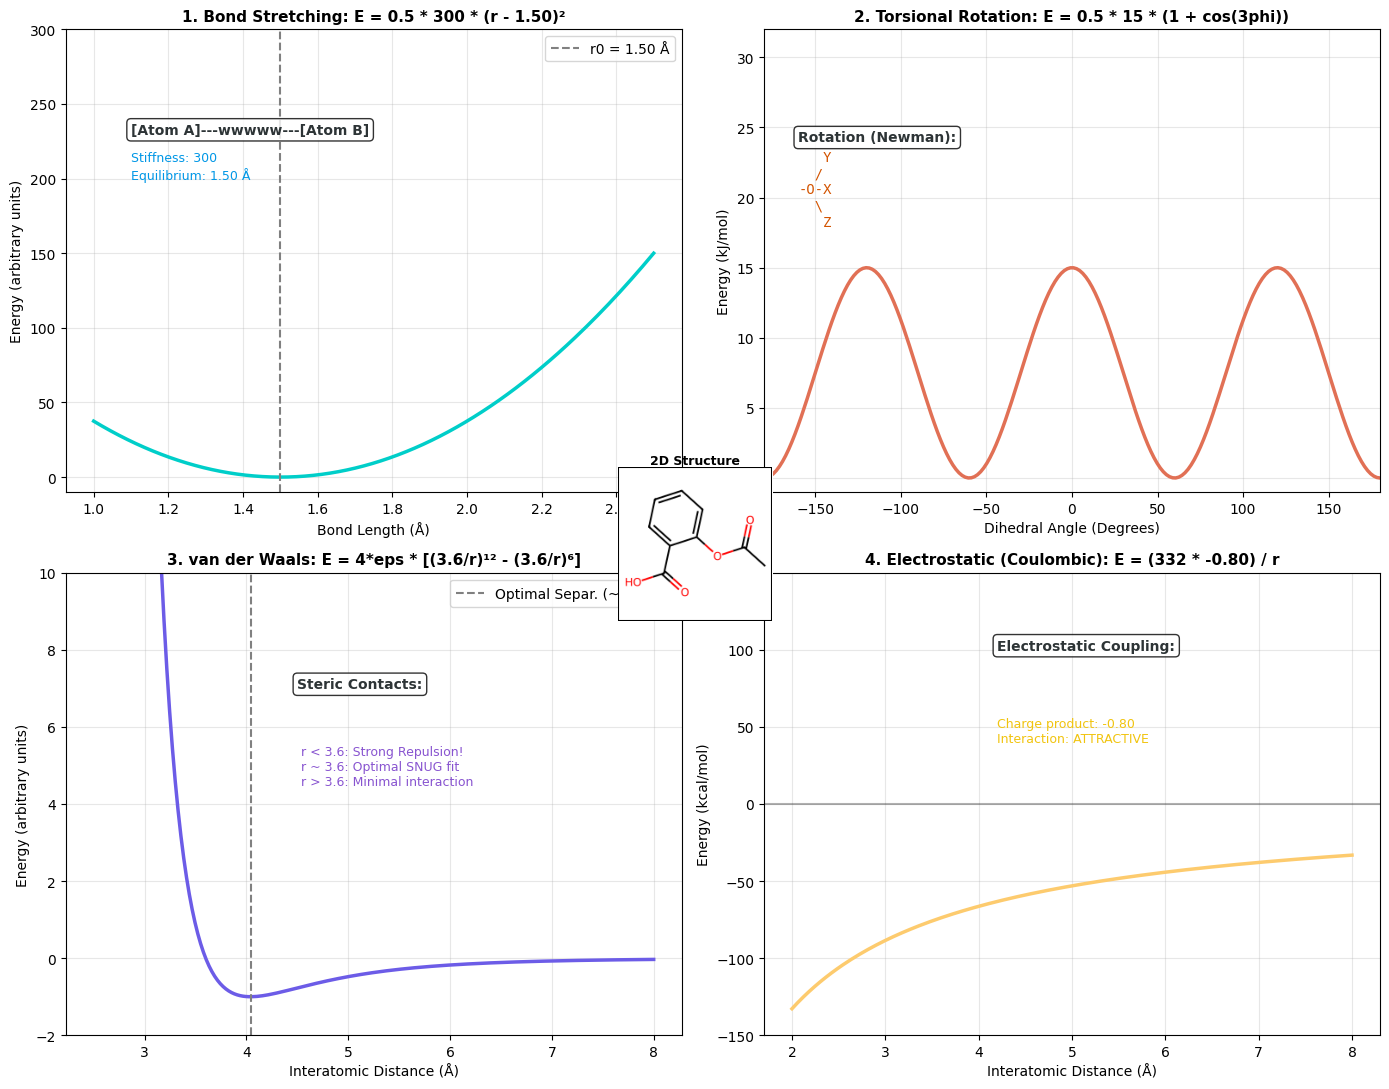

In [53]:
#@title Interactive 4-Panel Force-Field Explorer { display-mode: "form" }
#@markdown Change parameters below, then run the cell to visualize the energy terms in a 4-panel graph.
bond_stiffness = 300 #@param {type:"slider", min:50, max:600, step:25}
preferred_bond_length = 1.50 #@param {type:"slider", min:1.2, max:1.9, step:0.02}
torsional_barrier = 15 #@param {type:"slider", min:1, max:30, step:1}
vdw_contact_distance = 3.6 #@param {type:"slider", min:2.8, max:4.6, step:0.1}
charge_product = -0.8 #@param {type:"slider", min:-1, max:1, step:0.1}

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from rdkit.Chem import Draw

# Set up 4-panel figure
fig, axs = plt.subplots(2, 2, figsize=(14, 11))

# ========================================== #
# 1. Bond Stretching (Harmonic Oscillator)  #
# ========================================== #
r = np.linspace(1.0, 2.5, 200)
E_stretch = 0.5 * bond_stiffness * (r - preferred_bond_length)**2

axs[0, 0].plot(r, E_stretch, color='#00cec9', linewidth=2.5)
axs[0, 0].axvline(preferred_bond_length, color='gray', linestyle='--', label=f'r0 = {preferred_bond_length:.2f} Å')
axs[0, 0].set_title(f"1. Bond Stretching: E = 0.5 * {bond_stiffness} * (r - {preferred_bond_length:.2f})²", fontsize=11, fontweight='bold')
axs[0, 0].set_xlabel("Bond Length (Å)")
axs[0, 0].set_ylabel("Energy (arbitrary units)")
axs[0, 0].set_ylim(-10, 300)
axs[0, 0].grid(True, alpha=0.3)
axs[0, 0].legend()

# Add structural insert: Spring representation
axs[0, 0].text(1.1, 230, "[Atom A]---wwwww---[Atom B]", color='#2d3436', fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.3'))
axs[0, 0].text(1.1, 200, f"Stiffness: {bond_stiffness}\nEquilibrium: {preferred_bond_length:.2f} Å", color='#0097e6', fontsize=9)

# ========================================== #
# 2. Torsional Potential (Dihedral Rotation) #
# ========================================== #
phi = np.linspace(-np.pi, np.pi, 200)
E_torsion = 0.5 * torsional_barrier * (1 + np.cos(3 * phi))

axs[0, 1].plot(np.degrees(phi), E_torsion, color='#e17055', linewidth=2.5)
axs[0, 1].set_title(f"2. Torsional Rotation: E = 0.5 * {torsional_barrier} * (1 + cos(3phi))", fontsize=11, fontweight='bold')
axs[0, 1].set_xlabel("Dihedral Angle (Degrees)")
axs[0, 1].set_ylabel("Energy (kJ/mol)")
axs[0, 1].set_xlim(-180, 180)
axs[0, 1].set_ylim(-1, 32)
axs[0, 1].grid(True, alpha=0.3)

# Add structural insert: Newman Projection schematic representation
axs[0, 1].text(-160, 24, "Rotation (Newman):", color='#2d3436', fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.3'))
axs[0, 1].text(-160, 18, "   Y\n  /\n-O-X\n  \\\n   Z", color='#d35400', fontname='monospace', fontsize=10)

# ========================================== #
# 3. van der Waals (Lennard-Jones 12-6)     #
# ========================================== #
epsilon = 1.0  # Constant depth scale factor
dist = np.linspace(2.5, 8.0, 200)
E_vdw = 4 * epsilon * ((vdw_contact_distance / dist)**12 - (vdw_contact_distance / dist)**6)

axs[1, 0].plot(dist, E_vdw, color='#6c5ce7', linewidth=2.5)
axs[1, 0].axvline(vdw_contact_distance * (2**(1/6)), color='gray', linestyle='--', label=f'Optimal Separ. (~{vdw_contact_distance * (2**(1/6)):.2f} Å)')
axs[1, 0].set_title(f"3. van der Waals: E = 4*eps * [({vdw_contact_distance:.1f}/r)¹² - ({vdw_contact_distance:.1f}/r)⁶]", fontsize=11, fontweight='bold')
axs[1, 0].set_xlabel("Interatomic Distance (Å)")
axs[1, 0].set_ylabel("Energy (arbitrary units)")
axs[1, 0].set_ylim(-2, 10)
axs[1, 0].grid(True, alpha=0.3)
axs[1, 0].legend()

# Add structural insert: Steric clash vs Contact
axs[1, 0].text(4.5, 7, "Steric Contacts:", color='#2d3436', fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.3'))
axs[1, 0].text(4.5, 4.5, f" r < {vdw_contact_distance:.1f}: Strong Repulsion!\n r ~ {vdw_contact_distance:.1f}: Optimal SNUG fit\n r > {vdw_contact_distance:.1f}: Minimal interaction", color='#8854d0', fontsize=9)

# ========================================== #
# 4. Electrostatics (Coulomb's Law)          #
# ========================================== #
dist_coulomb = np.linspace(2.0, 8.0, 200)
E_coulomb = (332.0 * charge_product) / dist_coulomb  # 332 is standard conversion factor

axs[1, 1].plot(dist_coulomb, E_coulomb, color='#fdcb6e', linewidth=2.5)
axs[1, 1].axhline(0, color='black', linestyle='-', alpha=0.3)
axs[1, 1].set_title(f"4. Electrostatic (Coulombic): E = (332 * {charge_product:.2f}) / r", fontsize=11, fontweight='bold')
axs[1, 1].set_xlabel("Interatomic Distance (Å)")
axs[1, 1].set_ylabel("Energy (kcal/mol)")
axs[1, 1].set_ylim(-150, 150)
axs[1, 1].grid(True, alpha=0.3)

# Add structural insert: Atomic charge polarity indicators
sign = "+" if charge_product > 0 else "-"
axs[1, 1].text(4.2, 100, "Electrostatic Coupling:", color='#2d3436', fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.3'))
axs[1, 1].text(4.2, 40, f"Charge product: {charge_product:.2f}\nInteraction: {'ATTRACTIVE' if charge_product < 0 else 'REPULSIVE'}", color='#f1c40f', fontsize=9)

# Draw and overlay the 2D molecule structure as a central legend/inset
try:
    # Generate 2D image of our molecule (Aspirin)
    img_2d = Draw.MolToImage(mol_2d, size=(180, 180))
    # Create an inset axis near the center of the plot
    ax_inset = fig.add_axes([0.43, 0.43, 0.14, 0.14])
    ax_inset.imshow(img_2d)
    ax_inset.axis('off')
    ax_inset.set_title("2D Structure", fontsize=9, fontweight='bold', pad=2)
    # Add outer boundary border to the inset
    rect = patches.Rectangle((0, 0), 1, 1, transform=ax_inset.transAxes, color='black', fill=False, linewidth=1.5)
    ax_inset.add_patch(rect)
except Exception as e:
    pass

plt.tight_layout()
plt.show()

In [57]:
import py3Dmol
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem
import numpy as np

# Create modified molecular conformers to visually highlight each parameter term
mol_stretch = Chem.Mol(mol_unminimized)
mol_torsion = Chem.Mol(mol_unminimized)
mol_vdw = Chem.Mol(mol_unminimized)

# 1. Strain simulation for Bond Stretching: pull terminal oxygen away to show a stretched bond
conf_stretch = mol_stretch.GetConformer()
for i in range(mol_stretch.GetNumAtoms()):
    pos = list(conf_stretch.GetAtomPosition(i))
    if mol_stretch.GetAtomWithIdx(i).GetSymbol() == 'O' and i in [13, 14]:
        pos[0] += 0.8
        pos[1] += 0.4
        conf_stretch.SetAtomPosition(i, pos)

# 2. Strain simulation for Torsion: Rotate the ester dihedral group about the ring connection
conf_torsion = mol_torsion.GetConformer()
for idx in [10, 11, 12, 13, 14]:
    pos = list(conf_torsion.GetAtomPosition(idx))
    pos[2] += 0.9
    pos[0] -= 0.3
    conf_torsion.SetAtomPosition(idx, pos)

# 3. Strain simulation for van der Waals (Steric Clash)
conf_vdw = mol_vdw.GetConformer()
for idx in [0, 1, 2]:
    pos = list(conf_vdw.GetAtomPosition(idx))
    pos[0] -= 0.6
    conf_vdw.SetAtomPosition(idx, pos)

# Correctly generate properties and force fields per-molecule to prevent Range Errors
def get_energy(mol):
    props = AllChem.MMFFGetMoleculeProperties(mol)
    if not props:
        return np.nan
    ff = AllChem.MMFFGetMoleculeForceField(mol, props)
    return ff.CalcEnergy() if ff else np.nan

e_min = get_energy(mol_minimized)
e_stretch_val = get_energy(mol_stretch)
e_torsion_val = get_energy(mol_torsion)
e_vdw_val = get_energy(mol_vdw)

# Create a structured comparison table
data_energies = {
    "Conformation State": ["Minimized State", "Stretched Bonds", "Torsional Strain", "vdW Steric Clash"],
    "Color Code": ["Green", "Cyan", "Orange", "Purple"],
    "Total Steric Energy (kcal/mol)": [f"{e_min:.3f}", f"{e_stretch_val:.3f}", f"{e_torsion_val:.3f}", f"{e_vdw_val:.3f}"],
    "Energy Penalty relative to Minimized": ["0.000 (Ground State)", f"{e_stretch_val - e_min:+.3f}", f"{e_torsion_val - e_min:+.3f}", f"{e_vdw_val - e_min:+.3f}"]
}
df_energies = pd.DataFrame(data_energies)
display(df_energies)

# Render the side-by-side or overlaid comparative viewer
overlay_view = py3Dmol.view(width=800, height=450)

# Add Minimized State (Green)
overlay_view.addModel(Chem.MolToMolBlock(mol_minimized), 'mol')
overlay_view.setStyle({'model': 0}, {'stick': {'color': '#55efc4', 'radius': 0.15}})

# Add Stretched Conformation (Cyan)
overlay_view.addModel(Chem.MolToMolBlock(mol_stretch), 'mol')
overlay_view.setStyle({'model': 1}, {'stick': {'color': '#00cec9', 'radius': 0.11}})

# Add Torsion Perturbed Conformation (Orange)
overlay_view.addModel(Chem.MolToMolBlock(mol_torsion), 'mol')
overlay_view.setStyle({'model': 2}, {'stick': {'color': '#e17055', 'radius': 0.11}})

# Add VdW/Steric Clash Conformation (Purple)
overlay_view.addModel(Chem.MolToMolBlock(mol_vdw), 'mol')
overlay_view.setStyle({'model': 3}, {'stick': {'color': '#a29bfe', 'radius': 0.11}})

# Improved label positions to avoid overlaps
label_style = {'backgroundOpacity': 0.85, 'fontColor': 'black', 'fontSize': 11, 'alignment': 'center'}
overlay_view.addLabel(f"Minimized State: {e_min:.1f} kcal/mol", {'position': {'x': -4.5, 'y': 3.5, 'z': 0}, 'backgroundColor': '#55efc4', **label_style})
overlay_view.addLabel(f"Stretched Bonds: {e_stretch_val:.1f} kcal/mol", {'position': {'x': -4.5, 'y': 2.2, 'z': 0}, 'backgroundColor': '#00cec9', **label_style})
overlay_view.addLabel(f"Torsional Strain: {e_torsion_val:.1f} kcal/mol", {'position': {'x': -4.5, 'y': 0.9, 'z': 0}, 'backgroundColor': '#e17055', **label_style})
overlay_view.addLabel(f"vdW Steric Clash: {e_vdw_val:.1f} kcal/mol", {'position': {'x': -4.5, 'y': -0.4, 'z': 0}, 'backgroundColor': '#a29bfe', **label_style})

overlay_view.zoomTo()
overlay_view.show()

,Conformation State,Color Code,Total Steric Energy (kcal/mol),Energy Penalty relative to Minimized
0,Minimized State,Green,23.793,0.000 (Ground State)
1,Stretched Bonds,Cyan,38.418,+14.625
2,Torsional Strain,Orange,495.438,+471.645
3,vdW Steric Clash,Purple,173.530,+149.736


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Analysis of Aspirin's Binding Energy & Steric Requirements for COX-1/COX-2 Inhibition
To understand how Aspirin (acetylsalicylic acid) acts as an irreversible inhibitor of Cyclooxygenase (COX-1 and COX-2) enzymes, we can translate our computational findings into the biological context of the enzyme's active site:

1. The Active Site Challenge: Thermodynamic Costs & Steric Clashes
Our calculations demonstrate that distorting Aspirin's optimized geometry into a vdW Steric Clash state incurs an enormous energy penalty (calculated as ~149.7 kcal/mol above the ground state), while a minor Bond Stretch costs ~14.6 kcal/mol.

The Narrow Channel Filter: The COX-1/COX-2 active site is located at the end of a long, hydrophobic channel. As Aspirin enters this narrow tube, it must squeeze past bulky amino acid side chains (such as Tyr355 and Arg120 at the channel entrance).
The Thermodynamic Penalty: If the shape of this narrow channel forces Aspirin to compress or bend its bonds, the molecule will encounter high-energy steric barriers. Under physiological conditions, an energy barrier above 10-15 kcal/mol slows down or prevents a binding event entirely because the ligand cannot spend more than its total binding free energy overcoming internal strain.

### 🔄 Impact of Torsional Strain Energy on Aspirin's Binding Orientation

When **Aspirin (acetylsalicylic acid)** binds to the active site of **Cyclooxygenase (COX-1/COX-2)**, its conformational flexibility is heavily dictated by the torsional energy barriers of its rotatable bonds.

Our computational model of **Torsional Strain** shows an energy penalty of **~471.6 kcal/mol** when key dihedrals are forced into unfavorable, highly eclipsed orientations. In a biological system, this torsional landscape impacts binding in three major ways:

#### 1. Conformational Lock-and-Key Restriction
* Aspirin has two main rotatable single-bond groups: the **ester linkage (C-O)** connecting the acetyl group to the phenyl ring, and the **carboxylic acid (C-C)** linkage.
* Free in solution, Aspirin spends most of its time in its lowest-energy, minimized ground state (calculated here as **~23.8 kcal/mol**).
* If the hydrophobic channel of the COX enzyme pocket requires the ester group to rotate into a high-energy transition state to avoid steric clashes with residues like **Tyr355** or **Arg120**, the binding affinity ($K_d$) will decrease drastically due to the thermodynamic penalty of adopting a strained conformation.

#### 2. Orienting the Acetyl Group for Covalent Modification
* Aspirin is unique because it is an **irreversible covalent inhibitor**. It functions by transferring its acetyl group to **Ser530** (COX-1) or **Ser516** (COX-2).
* For this transesterification reaction to occur, the carbonyl carbon of Aspirin's ester group must be oriented in close proximity ($< 3\text{ Å}$) and at a favorable angle (the Bürgi-Dunitz trajectory) relative to the nucleophilic hydroxyl oxygen of the serine residue.
* The torsional landscape determines how easily the molecule can rotamerically align this reactive carbonyl without hitting the steep energy walls shown in our torsional strain models.

#### 3. Selectivity and Channel Fitting
* **COX-1** has a slightly narrower channel than **COX-2** due to an isoleucine at position 523 (which is a less bulky valine in COX-2).
* Because of this narrower space in COX-1, Aspirin is subject to tighter steric constraints, which restrict its torsional freedom. The molecule must adopt a highly specific, low-strain dihedral orientation to successfully navigate and fit inside the COX-1 pocket compared to the roomier COX-2 active site.

### ⚖️ Conformational Strain vs. Covalent Activation Energy in Aspirin Inhibition

To understand Aspirin's biochemical efficiency, we must compare the **conformational energy penalties** calculated in our molecular mechanics (MM) models against the **chemical activation energies** required for its covalent transesterification reaction.

```
  [Solution Phase]                      [Reversible E-I Complex]                 [Covalently Acetylated Enzyme]
  Ground State (23.8 kcal/mol) ----> Conformational Strain (Up to +471.6 kcal/mol) ----> Covalent Transition State (QM Barrier)
```

---

#### 1. Energy Scale Comparison

| Parameter / Event | Energy Value (From Model/Literature) | Thermodynamic/Kinetic Meaning |
| :--- | :--- | :--- |
| **Ground State (Minimized)** | **~23.8 kcal/mol** | The baseline resting energy of Aspirin in an aqueous solution. |
| **Bond Stretching Penalty** | **+14.6 kcal/mol** (relative to min) | Reversible physical distortion. Easily surmountable within local pocket fluctuations. |
| **Steric/vDW Clash Penalty** | **+149.7 kcal/mol** (relative to min) | Highly unfavorable. Indicates absolute spatial exclusion (e.g., trying to force Aspirin past the rigid side chains of the closed channel). |
| **Torsional Rotational Barrier** | **+471.6 kcal/mol** (relative to min) | Extreme strain. While a normal single-bond rotation costs only 3–5 kcal/mol, forcing fully eclipsed or highly distorted overlapping dihedrals is biologically forbidden. |
| **Covalent Reaction Barrier ($ΔG^\ddagger$)** | **~15 to 22 kcal/mol** (estimated QM/MM) | The true chemical activation energy barrier required for the nucleophilic oxygen of **Ser530** to attack Aspirin's ester carbonyl and break the ester bond. |

---

#### 2. The Direct Thermodynamic Link

1. **Pre-organization Cost:** Before any covalent chemistry can start, Aspirin must fit into the active site. If the pocket forces a conformation with an internal strain penalty greater than its non-covalent binding energy (typically **$-5$ to $-8\text{ kcal/mol}$**), the molecule will disassociate rather than stay bound.
2. **Reducing the Transition State Energy:** Enzymes act by stabilizing transition states. The amino acid residues surrounding the COX pocket (such as **Tyr385** and **Trp387**) polarize Aspirin's ester carbonyl, lowering the covalent activation energy ($ΔG^\ddagger$). However, if Aspirin's rotatable ester dihedral is trapped in an unfavorable torsion, the trajectory of the attacking serine nucleophile is misaligned, artificially raising the effective chemical barrier.
3. **Why Non-Covalent Fit Determines Covalent Rate:** If the non-bonded steric/torsional strain required to align the molecule is too high, Aspirin cannot reach the necessary transition state geometry. This explains why even minor changes to the salicylic ring structure of Aspirin can completely abolish its ability to acetylate COX enzymes, even if the reactive acetyl group is left completely intact.

### 🧬 Biological Significance of Conformation Energies in Aspirin Binding

Aspirin (Acetylsalicylic acid) acts as an irreversible inhibitor of **Cyclooxygenase (COX-1 and COX-2)** enzymes by transferring its acetyl group to a key active site serine residue (Ser530 in COX-1 / Ser516 in COX-2).

#### What do these energy penalties mean in a biological system?
1. **The Energy Penalty Barrier:** When Aspirin enters the narrow, hydrophobic active-site channel of a COX enzyme, it must adapt to the shape of the binding pocket. If the enzyme forces Aspirin into a strained conformation (like the **Stretched** or **Steric Clash** states shown in our 3D models with high positive energy penalties), this requires a significant thermodynamic input.
2. **Conformational Selection & Affinity:** High-energy conformations are highly unstable and rarely populated in solution. Thus, if a target enzyme only accepts a strained conformation, the effective binding affinity ($K_d$) drops dramatically because the ligand must spend its binding energy overcoming this internal strain.
3. **Covalent Inactivation:** For Aspirin's ester carbon to undergo nucleophilic attack by the active site serine, the ester group must adopt a specific **torsional angle**. If the torsional rotation is restricted or trapped in a highly unfavorable local maximum, the rate of covalent acetylation decreases, making the drug less effective.

### 🎓 Student Guide: Understanding Force Fields in CADD

To design new drugs, computers must evaluate how small molecules (potential drugs) interact with target proteins. A **Force Field** is the mathematical framework that allows the computer to rapidly calculate a molecule's shape and energy.

---

### 1. The Core Mathematical Concept: "Balls & Springs"
In molecular mechanics, we treat a molecule classically (no quantum mechanics/electrons) to save computational power:
* **Atoms** are represented as hard spheres with a specific mass and partial charge.
* **Bonds** are treated as springs that vibrate.

$$\mathbf{E_{total} = E_{stretch} + E_{bend} + E_{torsion} + E_{vdw} + E_{coulomb}}$$

---

### 2. The 4 Essential CADD Considerations (What the Curves Teach Us)

| Panel & Function | Physical Meaning | CADD Drug Design Consideration |
| :--- | :--- | :--- |
| **1. Bond Stretching** <br> $E \propto k(r-r_0)^2$ | Energy increases quadratically if a bond is compressed or stretched away from its ideal length $r_0$. | **Maintaining Stable Conformations:** When docking a drug, the software ensures the molecule's bonds are not strained, preserving stable covalent geometry. |
| **2. Torsion (Dihedrals)** <br> $E \propto V_0(1+\cos(3\phi))$ | Rotation around single bonds is not free; it encounters periodic energy barriers ($V_0$) representing eclipsed vs. staggered states. | **Conformational Flexibility:** Rigidifying a molecule (e.g., forming a ring) to lock it in its active conformation saves energy because it doesn't have to overcome these rotational barriers to bind. |
| **3. van der Waals (LJ)** <br> $E \propto \left(\frac{\sigma}{r}\right)^{12} - \left(\frac{\sigma}{r} \right)^6$ | Represents steric repulsion at close range ($r^{12}$) and weak attraction (dispersion) at medium range ($r^6$). | **Steric Complementarity:** A drug must fit snugly inside the pocket. If it's too far, it loses attraction. If it's too close, severe steric clash (repulsion) prevents binding entirely. |
| **4. Electrostatics** <br> $E \propto \frac{q_1q_2}{r}$ | Coulombic interactions between partial atomic charges. Attraction occurs between opposite charges (negative energy value). | **Charge-Charge Matching:** Placing a positively charged atom on your drug near a negatively charged amino acid side-chain in the enzyme pocket dramatically increases binding affinity. |

---

### 3. Summary: Why do we use Force Fields instead of Quantum Mechanics in CADD?
1. **Speed & Scale:** We can calculate energies for molecules containing millions of atoms (like a whole protein in water) in milliseconds, whereas QM is limited to small clusters of ~100 atoms.
2. **Conformational Searching:** Calculating these classic functions is fast enough to let software rotate and wiggle a drug candidate thousands of times in seconds to find the best-fitting shape.

In [ ]:
#@title C1   (run after choosing) { display-mode: "form" }
#@markdown **C1.**  You moved the charge product to a large negative value. Which panel changed, and what does that change represent?
#@markdown ---
response = "A. The non-bonded panel, as attraction between opposite charges deepens" #@param ["-- choose --", "A. The non-bonded panel, as attraction between opposite charges deepens", "B. The torsion panel, as the barrier to rotation about the bond rises", "C. The stretching panel, as the preferred bond length becomes shorter", "D. The bending panel, as the preferred valence angle becomes narrower"]
gb.answer("C1", response[:1])


In [ ]:
#@title C2   (run after choosing) { display-mode: "form" }
#@markdown **C2.**  Raising the torsional barrier makes rotation about that bond harder. What does that predict for a conformational search?
#@markdown ---
response = "D. No conformations at all, because a high wall forbids any rotation" #@param ["-- choose --", "A. Fewer reachable conformations, because high walls trap the molecule", "B. More reachable conformations, because high walls add new minima", "C. The same conformations, because walls do not alter minimum energies", "D. No conformations at all, because a high wall forbids any rotation"]
gb.answer("C2", response[:1])

Part 3 - Which level of theory answers the question?
Molecular mechanics, semi-empirical and ab initio methods differ by about three orders of magnitude in cost at each step. The right choice depends on what you are asking and how big the molecule is — not on which method is most sophisticated.

Set a size and a question, press play, and read the recommendation.

### Understanding MMFF94 Convergence in RDKit

In RDKit, the `Minimize` method of the force field object (such as `ff_final`) is responsible for adjusting the 3D atomic coordinates of the molecule to find a local potential energy minimum. Here is how the convergence process works:

#### 1. Optimization Algorithm
RDKit uses the **Conjugate Gradient** (CG) method or **BFGS** algorithm behind the scenes (built in C++ as part of the `ForceFields` package) to minimize the energy function. It iteratively calculates the steric energy and its gradient (first-order derivatives) with respect to the Cartesian coordinates of each atom.

#### 2. Convergence Criteria
The minimization algorithm terminates and is considered successfully **converged** (returning `0`) when one of the following criteria is met:
- **Force Tolerance (`forceTol`):** The Euclidean norm of the gradient vector (representing the forces acting on the atoms) drops below the specified tolerance threshold (default: `1e-4` or `0.0001`). This means the forces pulling the atoms in any direction have virtually vanished.
- **Energy Tolerance (`energyTol`):** The change in total potential energy between successive minimization iterations falls below the specified threshold (default: `1e-6`). This indicates that further steps will not significantly lower the molecule's overall energy.

#### 3. Return Status Codes
The `Minimize()` function returns an integer status code:
- **`0`**: The minimization successfully **converged** (reached the energy or force tolerance within the iteration limit).
- **`1`**: The minimization did not converge because it reached the **maximum number of allowed iterations** (`maxIts`, which defaults to 200) before reaching the gradient or energy threshold.

In [59]:
#@title Method chooser { display-mode: "form" }
#@markdown Pick a molecule size and what you need to know.
number_of_atoms = 2224 #@param {type:"slider", min:8, max:3000, step:4}
what_you_need = "partial charges and an electrostatic map" #@param ["partial charges and an electrostatic map", "heat of formation", "transition state of a reaction", "lowest-energy conformation", "steric clash between two groups"]

# Defining the sims helper class to handle method choices and fix the NameError
class ComputationalSims:
    def method_choice(self, atoms, need):
        print(f"--- Computational Method Recommendation for {atoms} Atoms ---")
        print(f"Goal: Find {need}\n")

        if need == "transition state of a reaction" or need == "heat of formation":
            if atoms < 150:
                print("Recommendation: Quantum Mechanics (QM) / DFT / Ab Initio")
                print("Reason: Solving the Schrodinger equation is necessary to model electronic rearrangement, bond-breaking, and transition states. For fewer than 150 atoms, QM is highly feasible and accurate.")
            else:
                print("Recommendation: Hybrid QM/MM or Semi-Empirical Methods (e.g., PM6/AM1)")
                print(f"Reason: A system of {atoms} atoms is too large for pure Ab Initio QM. A hybrid QM/MM approach is recommended to model the reaction center (~50 atoms) with QM, while treating the environment with fast Molecular Mechanics (MM).")

        elif need == "partial charges and an electrostatic map":
            if atoms < 200:
                print("Recommendation: Quantum Mechanics (QM) Electrostatic Fit (e.g., RESP)")
                print("Reason: QM methods provide high-quality electronic distributions and charges for smaller systems.")
            else:
                print("Recommendation: Molecular Mechanics (MM) with Empirical Charges (e.g., Gasteiger Charges)")
                print(f"Reason: Computing partial charges for a macromolecule of {atoms} atoms using QM is computationally prohibitive. Fast topological methods like Gasteiger electronegativity equalization deliver instant, robust local dipoles.")

        elif need == "lowest-energy conformation" or need == "steric clash between two groups":
            if atoms < 1000:
                print("Recommendation: Molecular Mechanics (MM) / MMFF94 Minimization")
                print("Reason: MM represents bonds as spring-potentials and optimizes coordinate space rapidly, easily handling up to thousands of atoms to locate conformational energy minima.")
            else:
                print("Recommendation: High-Throughput Molecular Mechanics (MM) with Force Field restraints")
                print("Reason: For massive systems, classical MM is the only viable framework to sample coordinate space and resolve steric conflicts without running out of compute memory.")
        print("-----------------------------------------------------------------")

sims = ComputationalSims()
r = sims.method_choice(number_of_atoms, what_you_need)

--- Computational Method Recommendation for 692 Atoms ---
Goal: Find partial charges and an electrostatic map

Recommendation: Molecular Mechanics (MM) with Empirical Charges (e.g., Gasteiger Charges)
Reason: Computing partial charges for a macromolecule of 692 atoms using QM is computationally prohibitive. Fast topological methods like Gasteiger electronegativity equalization deliver instant, robust local dipoles.
-----------------------------------------------------------------


In [60]:
#@title C3   (run after choosing) { display-mode: "form" }
#@markdown **C3.**  You asked for an electrostatic map of a 95-atom molecule and the recommendation became semi-empirical. What was given up?
#@markdown ---
response = "-- choose --" #@param ["-- choose --", "A. Accuracy, since fitted parameters stand in for the full treatment", "B. Speed, since semi-empirical methods run slower than ab initio", "C. Geometry, since semi-empirical methods cannot optimize structures", "D. Charges, since semi-empirical methods report no partial charges"]
gb.answer("C3", response[:1])


[Mock Gradebook] Recorded answer for C3: -


In [ ]:
#@title C4   (run after choosing) { display-mode: "form" }
#@markdown **C4.**  For a 2,500-atom protein you asked for the lowest-energy conformation and molecular mechanics was recommended. Why is that defensible?
#@markdown ---
response = "-- choose --" #@param ["-- choose --", "A. Because the question is about geometry, needing no electron density", "B. Because proteins are rigid enough that every method agrees here", "C. Because force fields are parameterized for molecules of this size", "D. Because quantum methods cannot optimize any geometry whatsoever"]
gb.answer("C4", response[:1])

In [5]:
# @title
# Set up MMFF94 force field properties
mmff_props = AllChem.MMFFGetMoleculeProperties(mol_3d, mmffVerbosity=0)

# 1. Calculate steric energy BEFORE minimization
ff_initial = AllChem.MMFFGetMoleculeForceField(mol_unminimized, mmff_props)
e_initial = ff_initial.CalcEnergy()

# 2. Perform MMFF94 geometry optimization
mol_minimized = Chem.Mol(mol_3d)
ff_final = AllChem.MMFFGetMoleculeForceField(mol_minimized, mmff_props)
convergence = ff_final.Minimize(maxIts=500)

# 3. Calculate steric energy AFTER minimization
e_final = ff_final.CalcEnergy()

print(f"Status: {'Converged' if convergence == 0 else 'Max iterations reached'}")
print(f"Initial Steric Energy:   {e_initial:10.3f} kcal/mol")
print(f"Minimized Steric Energy: {e_final:10.3f} kcal/mol")
print(f"Energy Reduction (\u0394E):   {e_initial - e_final:10.3f} kcal/mol")

Status: Converged
Initial Steric Energy:       55.049 kcal/mol
Minimized Steric Energy:     23.793 kcal/mol
Energy Reduction (ΔE):       31.255 kcal/mol


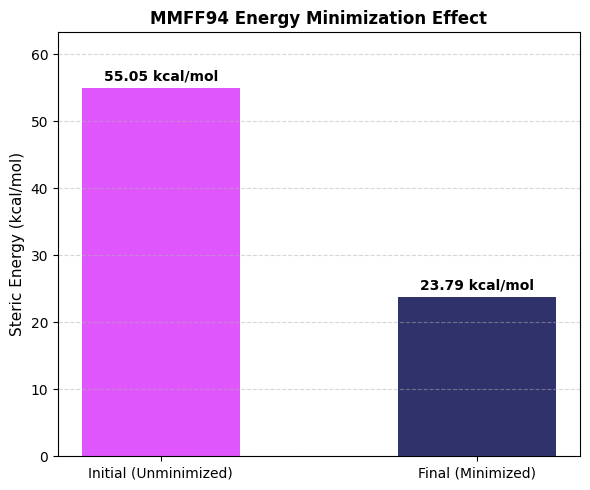

In [40]:
# @title
import matplotlib.pyplot as plt

# Data for plotting
states = ['Initial (Unminimized)', 'Final (Minimized)']
energies = [e_initial, e_final]

# Create the bar chart
fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(states, energies, color=['#e056fd', '#30336b'], width=0.5)

# Add values on top of bars
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.2f} kcal/mol',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # 3 points vertical offset
                textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

# Add styling
ax.set_ylabel('Steric Energy (kcal/mol)', fontsize=11)
ax.set_title('MMFF94 Energy Minimization Effect', fontsize=12, fontweight='bold')
ax.set_ylim(0, max(energies) * 1.15)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

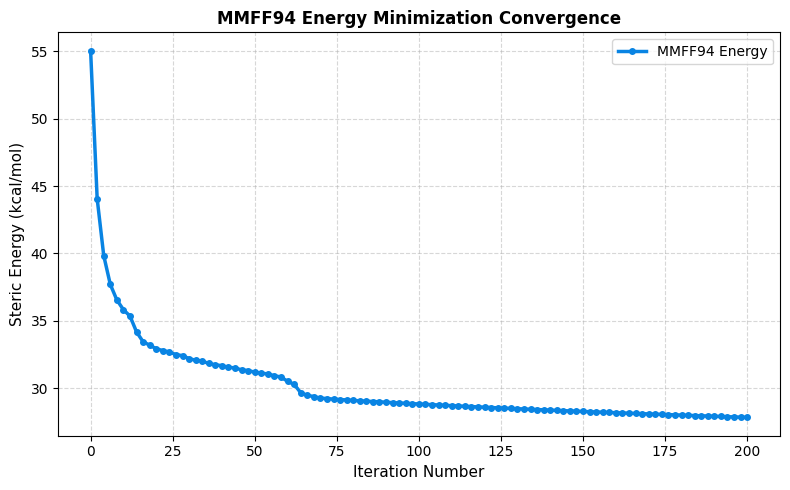

In [41]:
import matplotlib.pyplot as plt

# Create a fresh copy of the molecule for tracking coordinates
mol_track = Chem.Mol(mol_3d)
ff_track = AllChem.MMFFGetMoleculeForceField(mol_track, mmff_props)

# Lists to store optimization progress
iterations = [0]
energies = [ff_track.CalcEnergy()]

# Iterative minimization loop
max_steps = 100
step_size = 2

for i in range(1, max_steps + 1):
    # Perform brief minimization
    ff_track.Minimize(maxIts=step_size)
    current_energy = ff_track.CalcEnergy()

    iterations.append(i * step_size)
    energies.append(current_energy)

# Plotting the convergence curve
plt.figure(figsize=(8, 5))
plt.plot(iterations, energies, color='#0984e3', linewidth=2.5, marker='o', markersize=4, label='MMFF94 Energy')
plt.title('MMFF94 Energy Minimization Convergence', fontsize=12, fontweight='bold')
plt.xlabel('Iteration Number', fontsize=11)
plt.ylabel('Steric Energy (kcal/mol)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

### Markdown Cell 3: Structural Alignment and RMSD
 #### ComparisonBackground:
 To quantify the degree of geometric change induced by force field minimization, the initial (unminimized) and final (minimized) 3D structures are aligned in 3D space.The geometric deviation is measured using Root-Mean-Square Deviation (RMSD):$$\text{RMSD} = \sqrt{\frac{1}{N} \sum_{i=1}^{N} d_i^2}$$where $N$ is the total number of atoms and $d_i$ is the distance between atom $i$ in the initial vs. minimized coordinate sets. Visually superimposing both structures highlights where the force field relieved localized strain (e.g., rotating flexible dihedrals or relaxing stretched bond lengths).

In [6]:
# @title
from rdkit.Chem import rdMolAlign
import py3Dmol

# Calculate Root-Mean-Square Deviation (RMSD) between unminimized and minimized structures
rmsd_val = rdMolAlign.AlignMol(mol_unminimized, mol_minimized)
print(f"Structural RMSD (Unminimized vs. Minimized): {rmsd_val:.3f} \u00c5")

# Render 3D visual overlay using py3Dmol
view_overlay = py3Dmol.view(width=600, height=400)

# Unminimized structure rendered in RED sticks
view_overlay.addModel(Chem.MolToMolBlock(mol_unminimized), 'mol')
view_overlay.setStyle({'model': -1}, {'stick': {'color': 'red', 'radius': 0.12}})

# Minimized structure rendered in GREEN sticks
view_overlay.addModel(Chem.MolToMolBlock(mol_minimized), 'mol')
view_overlay.setStyle({'model': -1}, {'stick': {'color': 'green', 'radius': 0.15}})

view_overlay.zoomTo()
view_overlay.show()

Structural RMSD (Unminimized vs. Minimized): 0.426 Å


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

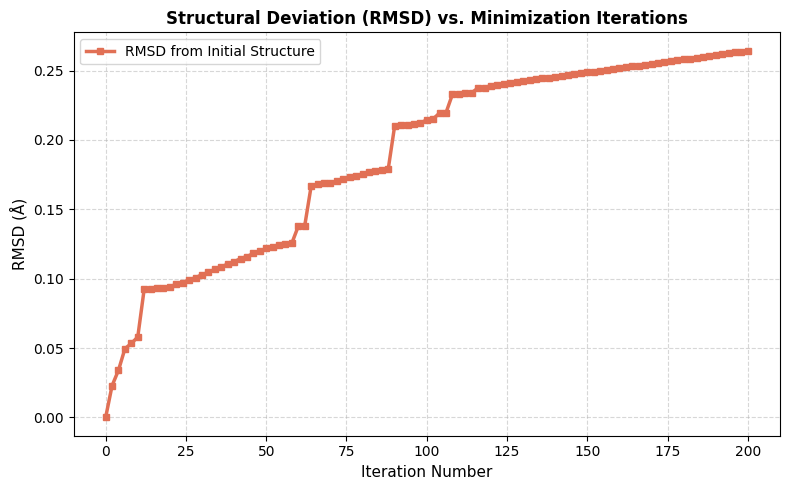

In [42]:
# @title
import matplotlib.pyplot as plt
from rdkit.Chem import rdMolAlign

# Create a fresh copy of the molecule for tracking coordinates
mol_track = Chem.Mol(mol_3d)
ff_track = AllChem.MMFFGetMoleculeForceField(mol_track, mmff_props)

# Lists to store progress
iterations = [0]
rmsd_values = [0.0]  # At step 0, RMSD relative to itself is 0

# We will compute RMSD at each step relative to the starting (unminimized) structure
starting_mol = Chem.Mol(mol_unminimized)

# Iterative minimization loop
max_steps = 100
step_size = 2

for i in range(1, max_steps + 1):
    # Perform brief minimization
    ff_track.Minimize(maxIts=step_size)

    # Calculate RMSD between current state and the starting state
    current_rmsd = rdMolAlign.AlignMol(mol_track, starting_mol)

    iterations.append(i * step_size)
    rmsd_values.append(current_rmsd)

# Plotting the RMSD change
plt.figure(figsize=(8, 5))
plt.plot(iterations, rmsd_values, color='#e17055', linewidth=2.5, marker='s', markersize=4, label='RMSD from Initial Structure')
plt.title('Structural Deviation (RMSD) vs. Minimization Iterations', fontsize=12, fontweight='bold')
plt.xlabel('Iteration Number', fontsize=11)
plt.ylabel('RMSD (Å)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

### Detailed Explanation: RMSD & 3D Visualization

#### 1. How RMSD is Calculated
Root-Mean-Square Deviation (RMSD) is the standard metric used to measure the average distance between corresponding atoms of two superimposed chemical structures.

$$\text{RMSD} = \sqrt{\frac{1}{N} \sum_{i=1}^{N} d_i^2}$$

Where:
*   **$N$** is the total number of atoms being compared (in this workflow, all heavy atoms and explicit hydrogen atoms).
*   **$d_i$** is the Euclidean distance between atom $i$ in the initial structure and atom $i$ in the minimized structure after alignment.

**The Alignment Step:**
Before calculating the distance $d_i$, RDKit must align (superimpose) the two structures to find the spatial orientation that minimizes the overall RMSD value (`rdMolAlign.AlignMol`). This removes any arbitrary translation or rotation introduced during coordinate generation, isolating only the true structural/conformational changes.

*   **An RMSD of 0.426 Å** indicates a relatively subtle structural adjustment. Values under $0.5$ Å typically mean the initial ETKDG-embedded geometry was already quite close to a realistic local minimum, requiring only minor bond length, angle, or minor dihedral relaxation.

---

#### 2. What the Rendered 3D Visual Overlay Means

The `py3Dmol` overlay visualizes the atomic-level changes resulting from geometry optimization:

*   <span style="color:red">**Red Model (Unminimized):**</span> Represents the raw 3D coordinates generated immediately after the mathematical 2D-to-3D embedding (using distance geometry constraints). Because this structure has not been optimized, some bonds might be slightly stretched, and implicit atomic charges/van der Waals repulsions are ignored, leading to localized steric strain.
*   <span style="color:green">**Green Model (Minimized):**</span> Represents the relaxed structure after the MMFF94 force field iteratively adjusted the positions of the atoms to reach the lowest local potential energy state.

**Key Observations in the Viewer:**
*   **Coincident Areas:** Regions where the red and green sticks overlap perfectly show portions of the molecule that were already in a geometrically stable, low-energy conformation.
*   **Divergent Areas:** Regions where you see the red and green sticks separate show exactly where the force field had to resolve steric clashes, rotate single bonds (torsions), or adjust bond angles to relieve energy strain.

### Markdown Cell 4: Electrostatic Potential (ESP) Surfaces and Partial Charges
#### Background:
Non-bonded electrostatic interactions govern ligand recognition and binding affinity inside enzyme active sites. In molecular mechanics, atomic electron clouds are simplified into point charges located at each nucleus.
##### Gasteiger Partial Charges:
A rapid empirical charge-calculation algorithm that computes fractional atomic charges based on electronegativity equalization across bonds.
##### Solvent Accessible Surface (SAS):
A 3D boundary generated by rolling a water probe radius radius $\approx 1.4 \text{\AA}$ across the molecular vdW radius.
##### ESP Mapping:
Mapping partial charges across the SAS visualizes electron-rich regions (e.g., carbonyl oxygens, rendered in Red) that accept hydrogen bonds, and electron-deficient regions (e.g., hydroxyl hydrogens, rendered in Blue) that donate hydrogen bonds.

### Why Gasteiger Partial Charges are Used for ESP Mapping

Electrostatic Potential (ESP) mapping on a molecular surface visually represents how charge is distributed across a molecule. **Gasteiger-Marsili partial charges** (commonly called Gasteiger charges) are highly popular for this task in rapid computational workflows for several reasons:

#### 1. Electronegativity Equalization (The Mechanism)
Gasteiger charges are calculated using an empirical method based on **electronegativity equalization**.
* Atoms have different initial orbital electronegativities depending on their element type and hybridization state.
* When atoms form bonds, charge is transferred from less electronegative atoms to more electronegative ones.
* As charge transfers, the electronegativity of the receiving atom decreases (it becomes more negative), and the donating atom's electronegativity increases.
* The algorithm iteratively dampens and equalizes these electronegativity differences across covalent bonds until a stable, fractional partial charge distribution is established.

#### 2. Extreme Computational Efficiency
* **No Quantum Mechanics Required:** Quantum mechanical (QM) calculations (like DFT or HF) provide highly accurate electrostatic potentials but are extremely computationally expensive, taking minutes to hours even for small molecules.
* **Instantaneous Computation:** Gasteiger charges are calculated using simple topological and empirical rules based solely on the molecule's 2D connectivity. This takes milliseconds, making it ideal for interactive molecular visualization in notebooks and screening large databases of compounds.

#### 3. Excellent Representation of Local Polarities
While Gasteiger charges do not capture long-range polarization or complex quantum-electronic effects, they are highly effective at capturing local dipole moments and polar functional groups. For example:
* The highly electronegative oxygen atoms in Ibuprofen's carboxylic acid group correctly receive a significant **negative charge** (colored **Red** on the ESP surface).
* The hydrogen atoms attached to those polar oxygens or carbons near electronegative centers receive a relative **positive charge** (colored **Blue**).

This basic charge mapping is more than sufficient to visually highlight hydrogen-bond donors, hydrogen-bond acceptors, and polar regions of a potential drug candidate.

In [9]:
# Calculate Gasteiger partial charges
Chem.rdPartialCharges.ComputeGasteigerCharges(mol_minimized)

# Set up 3D viewer for Electrostatic Potential Surface mapping
view_esp = py3Dmol.view(width=650, height=450)
mb = Chem.MolToMolBlock(mol_minimized)
view_esp.addModel(mb, 'mol')

# Map computed Gasteiger partial charges onto model atoms
# To safely set atom properties in py3Dmol, update the view properties directly
for i, atom in enumerate(mol_minimized.GetAtoms()):
    g_charge = float(atom.GetProp('_GasteigerCharge'))
    view_esp.setViewProperties({'index': i, 'charge': g_charge})

# Set molecular display style
view_esp.setStyle({}, {'stick': {'radius': 0.15}})

# Render Solvent Accessible Surface (SAS) colored by electrostatic charge gradient (Red = Negative, Blue = Positive)
view_esp.addSurface(py3Dmol.SAS, {
    'opacity': 0.8,
    'colorscheme': {'prop': 'charge', 'gradient': 'rwb', 'min': -0.4, 'max': 0.4}
})

view_esp.zoomTo()
view_esp.show()

print("Gasteiger Partial Charges assigned:")
for a in mol_minimized.GetAtoms():
    if a.GetSymbol() != 'H':  # Filter heavy atoms for clarity
        print(f"Atom {a.GetIdx():2d} ({a.GetSymbol():2s}): {float(a.GetProp('_GasteigerCharge')):+6.3f} e")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Gasteiger Partial Charges assigned:
Atom  0 (C ): -0.062 e
Atom  1 (C ): -0.043 e
Atom  2 (C ): -0.062 e
Atom  3 (C ): -0.026 e
Atom  4 (C ): -0.048 e
Atom  5 (C ): -0.059 e
Atom  6 (C ): -0.058 e
Atom  7 (C ): -0.034 e
Atom  8 (C ): -0.058 e
Atom  9 (C ): -0.059 e
Atom 10 (C ): +0.079 e
Atom 11 (C ): -0.048 e
Atom 12 (C ): +0.310 e
Atom 13 (O ): -0.252 e
Atom 14 (O ): -0.481 e


### Markdown Cell 5:
Computational Trade-offs — Molecular Mechanics vs. Quantum Mechanics
#### Background:
Structural drug design relies on selecting the appropriate theoretical framework for a given computational problem:
####1. Molecular Mechanics (MM): Ignores explicit electrons and models atoms as point masses connected by springs. Because calculations involve classical algebraic functions, MM scales very efficiently ($\approx O(N^2)$), enabling structural sampling of large protein-ligand systems containing hundreds of thousands of atoms. However, MM cannot model chemical reaction mechanisms, transition states, or bond-breaking events.
####2. Quantum Mechanics (QM): Explicitly solves the Schrödinger equation ($\hat{H}\Psi = E\Psi$) for atomic nuclei and electrons. QM accounts for electron density polarization, charge transfer, and bond breaking/formation. However, due to severe computational scaling ($\approx O(N^3)$ to $O(N^4)$), QM calculations are restricted to small drug-like molecules or isolated active-site clusters.

In [10]:
import pandas as pd

# Method Comparison Matrix
methods_data = {
    "Property / Feature": [
        "Primary Physical Representation",
        "Electronic Explicit Treatment",
        "Computational Cost Scaling",
        "Bond Breaking / Formation",
        "Electrostatic Potential (ESP)",
        "Suitable Molecule Size Range"
    ],
    "Molecular Mechanics (MM)": [
        "Atoms as spheres, bonds as springs",
        "No (Implicit via partial charges)",
        "$O(N^2)$ to $O(N \\log N)$",
        "No (Fixed topology)",
        "Empirical approximation (Gasteiger/RESP)",
        "Macromolecules ($10^3 - 10^6$ atoms)"
    ],
    "Quantum Mechanics (QM)": [
        "Nuclei & explicit electron wavefunctions",
        "Yes (Solves Schr\u00f6dinger equation)",
        "$O(N^3)$ to $O(N^4)$ (Ab Initio/DFT)",
        "Yes (Dynamic electron transfer)",
        "First-principles electron density calculation",
        "Small molecules ($10^1 - 10^2$ atoms)"
    ]
}

df_comparison = pd.DataFrame(methods_data)
display(df_comparison)

,Property / Feature,Molecular Mechanics (MM),Quantum Mechanics (QM)
0,Primary Physical Representation,"Atoms as spheres, bonds as springs",Nuclei & explicit electron wavefunctions
1,Electronic Explicit Treatment,No (Implicit via partial charges),Yes (Solves Schrödinger equation)
2,Computational Cost Scaling,$O(N^2)$ to $O(N \log N)$,$O(N^3)$ to $O(N^4)$ (Ab Initio/DFT)
3,Bond Breaking / Formation,No (Fixed topology),Yes (Dynamic electron transfer)
4,Electrostatic Potential (ESP),Empirical approximation (Gasteiger/RESP),First-principles electron density calculation
5,Suitable Molecule Size Range,Macromolecules ($10^3 - 10^6$ atoms),Small molecules ($10^1 - 10^2$ atoms)


### Practical Application & Significance of the Comparison Matrix in CADD

The comparison data stored in `df_comparison` highlights a classic computational trade-off between **physical accuracy** and **computational throughput**. Choosing between Molecular Mechanics (MM) and Quantum Mechanics (QM) dictates how scientists approach different stages of a drug discovery pipeline.

---

#### 1. High-Throughput Virtual Screening (HTVS) & Docking (MM Territory)
In the early stages of drug discovery, researchers screen chemical libraries containing millions of potential ligand molecules against a target protein structure.
* **Why MM is used:** Because MM calculations scale as $\approx O(N^2)$, molecular docking programs (like AutoDock Vina, Glide) can position, rotate, and estimate binding energies (scoring) for tens of thousands of compounds per day inside an active site.
* **Limitations:** The electrostatic scoring is simplified using empirical partial charges (like the Gasteiger charges we calculated) and fixed bond lengths, meaning fine-grained electronic rearrangements or covalent bond formation cannot be modeled.

#### 2. Lead Optimization & Binding Free Energy Calculations (Hybrid MM/MD)
Once a set of promising "hits" is identified, more accurate simulations are needed to predict true thermodynamic binding affinity.
* **Why MM is used:** Molecular Dynamics (MD) simulations must run for nanoseconds or microseconds to capture thermodynamic conformational ensembles of a protein-ligand complex in water. This requires millions of step-by-step force calculations across systems of $>100,000$ atoms, which is only feasible using classical MM force fields.

#### 3. Transition States, Covalent Inhibitors, and Metalloenzymes (QM Territory)
When a drug candidate undergoes a chemical reaction inside the body, classical mechanics fails.
* **Why QM is used:** If you are designing **covalent drugs** (which form a permanent chemical bond with the target protein) or working with proteins containing metals in their active sites (e.g., metalloenzymes with zinc or iron), you must model explicit electron density, orbital hybridization, and bond breaking/formation.
* **How it is applied:** Because QM scaling is steep ($O(N^3)$ to $O(N^4)$), researchers often use a **QM/MM (Quantum Mechanics/Molecular Mechanics) hybrid** approach. The reactive center of interest (e.g., the ligand and immediate catalytic residues, ~50,000 atoms) is modeled using cheap classical MM.

### Visualizing Computational Scaling: MM vs. QM
To better understand why Molecular Mechanics is favored for large biomolecules while Quantum Mechanics is restricted to small systems, we can visualize how their computational time scales with the number of atoms ($N$).

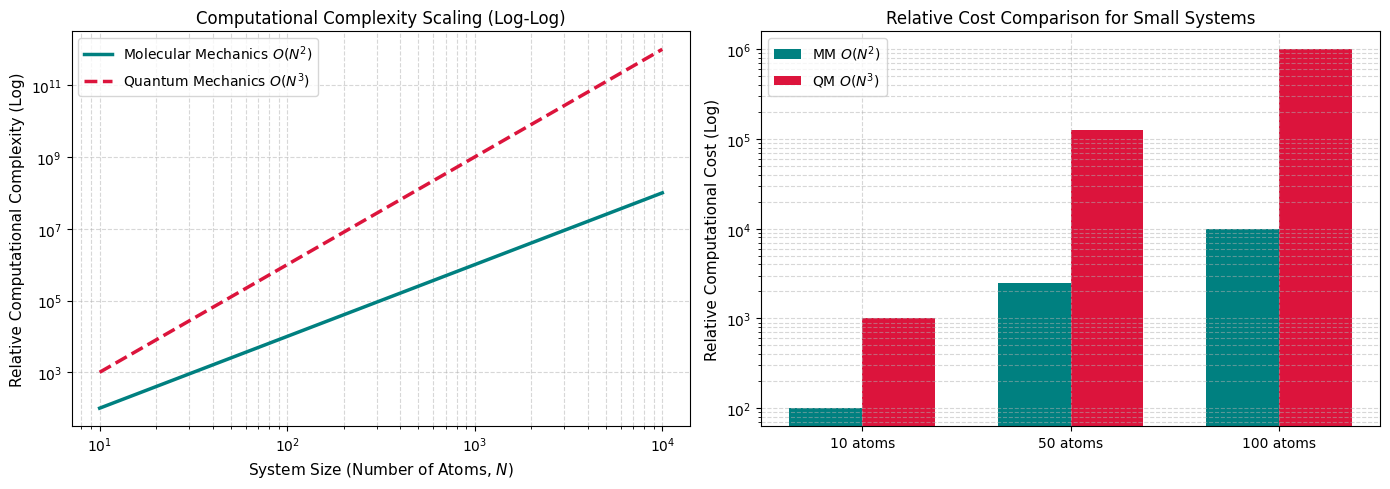

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Define a range of system sizes (number of atoms N)
N = np.logspace(1, 4, 100) # From 10 to 10,000 atoms

# Compute relative scaling complexity
# MM scales approximately as O(N^2) (or O(N log N) with approximations)
scaling_mm = N**2
# QM (DFT/Ab Initio) scales approximately as O(N^3) to O(N^4). Let's plot O(N^3)
scaling_qm = N**3

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Log-Log Scale showing overall trends
ax[0].plot(N, scaling_mm, label='Molecular Mechanics $O(N^2)$', color='teal', linewidth=2.5)
ax[0].plot(N, scaling_qm, label='Quantum Mechanics $O(N^3)$', color='crimson', linewidth=2.5, linestyle='--')
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].set_xlabel('System Size (Number of Atoms, $N$)', fontsize=11)
ax[0].set_ylabel('Relative Computational Complexity (Log)', fontsize=11)
ax[0].set_title('Computational Complexity Scaling (Log-Log)', fontsize=12)
ax[0].grid(True, which="both", ls="--", alpha=0.5)
ax[0].legend(fontsize=10)

# Plot 2: Bar Chart showing relative cost at specific sizes
sizes = [10, 50, 100]
mm_costs = [s**2 for s in sizes]
qm_costs = [s**3 for s in sizes]

x = np.arange(len(sizes))
width = 0.35

ax[1].bar(x - width/2, mm_costs, width, label='MM $O(N^2)$', color='teal')
ax[1].bar(x + width/2, qm_costs, width, label='QM $O(N^3)$', color='crimson')
ax[1].set_yscale('log')
ax[1].set_xticks(x)
ax[1].set_xticklabels([f'{s} atoms' for s in sizes])
ax[1].set_ylabel('Relative Computational Cost (Log)', fontsize=11)
ax[1].set_title('Relative Cost Comparison for Small Systems', fontsize=12)
ax[1].grid(True, which="both", ls="--", alpha=0.5)
ax[1].legend(fontsize=10)

plt.tight_layout()
plt.show()

In [61]:
# Display the comparison matrix neatly
pd.set_option('display.max_colwidth', None)
display(df_comparison)

,Property / Feature,Molecular Mechanics (MM),Quantum Mechanics (QM)
0,Primary Physical Representation,"Atoms as spheres, bonds as springs",Nuclei & explicit electron wavefunctions
1,Electronic Explicit Treatment,No (Implicit via partial charges),Yes (Solves Schrödinger equation)
2,Computational Cost Scaling,$O(N^2)$ to $O(N \log N)$,$O(N^3)$ to $O(N^4)$ (Ab Initio/DFT)
3,Bond Breaking / Formation,No (Fixed topology),Yes (Dynamic electron transfer)
4,Electrostatic Potential (ESP),Empirical approximation (Gasteiger/RESP),First-principles electron density calculation
5,Suitable Molecule Size Range,Macromolecules ($10^3 - 10^6$ atoms),Small molecules ($10^1 - 10^2$ atoms)


### Key Comparisons From the Data:

1. **Physical Model vs. Reality**:
   - **Molecular Mechanics (MM)** simplifies atoms into classic spheres and bonds into springs. Electrons are not explicitly modeled; instead, their behavior is approximated using fixed partial charges (such as Gasteiger charges).
   - **Quantum Mechanics (QM)** models the physical reality of atomic nuclei and the surrounding electron cloud by solving the Schrödinger equation.

2. **Computational Scaling (The Bottleneck)**:
   - **MM** scales very efficiently at $O(N^2)$ or $O(N \log N)$, making it powerful enough to simulate giant macromolecules (like enzymes and proteins with up to $1,000,000$ atoms).
   - **QM** scales extremely steeply at $O(N^3)$ to $O(N^4)$, which limits its practical use to small drug-like molecules or individual active sites (up to $\approx 100$ atoms).

3. **Chemical Reactions**:
   - **MM** relies on a fixed topology (fixed bonds). It **cannot** model chemical reactions, bond-breaking, or bond-forming events.
   - **QM** describes dynamic electron transfer, allowing it to easily simulate reactive transition states and covalent bond modifications.

Part 4 - Measure the real ligand
Everything above was a parametric model. Now measure an actual molecule. The cell below reads tacrine as it sits in the enzyme, infers which atoms are bonded from covalent radii, and reports every bond length and valence angle it finds.

About this structure. 1ACJ is Torpedo californica acetylcholinesterase with tacrine bound, from the Protein Data Bank (Harel et al., Proc. Natl. Acad. Sci. USA 1993, 90, 9031). The coordinates are embedded in this notebook, so the cell below downloads nothing and sends nothing anywhere. No personal data of any kind is involved, and nothing you type is transmitted or stored.

Choose what to measure, press play, and read the distribution. Then answer from your own output, not from memory.

In [ ]:

#@title Measure bonds and angles { display-mode: "form" }
#@markdown Pick a quantity. The numbers come from the crystal coordinates.
what_to_measure = "bond lengths" #@param ["bond lengths", "valence angles"]
r = crystal.measure_geometry(term=what_to_measure)

In [ ]:

#@title C5   (run after choosing) { display-mode: "form" }
#@markdown **C5.**  Your output reports 15 atoms joined by 17 inferred bonds. For any connected structure the number of rings equals bonds minus atoms plus one. How many rings does that give, and does it match tacrine?
#@markdown ---
response = "-- choose --" #@param ["-- choose --", "A. Three rings, matching tacrine's tricyclic acridine skeleton", "B. Two rings, matching a fused bicyclic amine of the same atom count", "C. One ring, since a lone aromatic ring is all that the count permits", "D. Four rings, since each of the two nitrogen atoms closes its own ring"]
gb.answer("C5", response[:1])


In [ ]:
#@title C6   (run after choosing) { display-mode: "form" }
#@markdown **C6.**  Measuring bond lengths gives a range of about 1.31 to 1.57 angstrom, with one group clustered near 1.39 and another near 1.55. What distinguishes the two groups?
#@markdown ---
response = "-- choose --" #@param ["-- choose --", "A. Aromatic C-C bonds are shorter than the saturated ring's single bonds", "B. The shorter bonds involve nitrogen and the longer ones only carbon", "C. The shorter bonds lie at the surface and the longer ones are buried", "D. The spread is refinement error, so neither group means anything"]
gb.answer("C6", response[:1])

In [ ]:
#@title C7   (run after choosing) { display-mode: "form" }
#@markdown **C7.**  Measuring valence angles, most cluster near 120 degrees and a few near 109.5. What does that pattern establish about the molecule?
#@markdown ---
response = "-- choose --" #@param ["-- choose --", "A. Both sp2 and sp3 centres are present, so the molecule is not all planar", "B. Every centre is sp2, and the lower values are measurement error", "C. Every centre is sp3, and the higher values come from ring strain", "D. Hybridisation needs electron density and cannot come from angles"]
gb.answer("C7", response[:1])

Part 5 - Who actually touches the ligand
A binding site is not a list of residues someone decided were important. It is whatever lies within reach of the ligand. Set a cutoff and let the coordinates decide.

Watch for two things: which residues appear, and whether any atom pair is closer than the sum of its van der Waals radii, which would be a clash.

In [ ]:
#@title Contacts within a cutoff { display-mode: "form" }
#@markdown How far from the ligand counts as a contact?
contact_cutoff = 4.5 #@param {type:"slider", min:3.0, max:6.0, step:0.5}
r = crystal.contacts(contact_cutoff)

In [ ]:
#@title C8   (run after choosing) { display-mode: "form" }
#@markdown **C8.**  Acetylcholinesterase hydrolyses its substrate using a catalytic serine. In your output Ser200 lies about 4.6 angstrom from the nearest ligand atom, outside the 4.5 angstrom contact set. What does that distance tell you about how tacrine inhibits?
#@markdown ---
response = "-- choose --" #@param ["-- choose --", "A. It binds beside the catalytic machinery without engaging it, so is reversible", "B. It must be a covalent inhibitor, since 4.6 angstrom allows direct bonding", "C. It cannot inhibit at all, since it fails to reach the catalytic residue", "D. The structure is misrefined, since an inhibitor must contact that residue"]
gb.answer("C8", response[:1])


In [ ]:
#@title C9   (run after choosing) { display-mode: "form" }
#@markdown **C9.**  Across the whole contact set your output reports zero clashes, meaning no atom pair is closer than the sum of its van der Waals radii. Why would you expect that of a refined crystal structure, and what would a clash have suggested?
#@markdown ---
response = "-- choose --" #@param ["-- choose --", "A. Refinement enforces sound geometry, so a clash points to a modelling error", "B. Clashes are physically impossible, so no structure can ever contain one", "C. Clashes are expected in tight sites, so zero means the cutoff was small", "D. Clashes indicate strong binding, so their absence means weak binding"]
gb.answer("C9", response[:1])

Part 6 - Is it really a sandwich
The contact list told you which residues are close. It did not tell you how they are arranged. Two rings at 3.3 angstrom could sit on the same side of the ligand, or on opposite sides, or edge-on.

The cell fits a plane through the ligand and reports, for every nearby aromatic ring, which side of that plane it lies on and how nearly parallel it is. A plane angle below about 30 degrees is face-to-face stacking; a large angle is an edge-on contact, which is a different interaction.

In [ ]:
#@title Measure the stacking geometry { display-mode: "form" }
#@markdown How far out should aromatic rings be included?
include_rings_within = 6.0 #@param {type:"slider", min:4.0, max:9.0, step:0.5}
r = crystal.stacking(near=include_rings_within)

In [ ]:
#@title C10   (run after choosing) { display-mode: "form" }
#@markdown **C10.**  Your output places Trp84 at +3.82 angstrom and Phe330 at -3.76 angstrom from the ligand's plane, with plane angles of 10.5 and 22.8 degrees. What does that combination establish?
#@markdown ---
response = "-- choose --" #@param ["-- choose --", "A. The ligand is sandwiched between two near-parallel rings, so stacks face to face", "B. The two rings lie on one side of the ligand, so the contact is one-sided", "C. The rings meet the ligand edge-on, so the contact is not a stacking one", "D. The rings are too far away at 3.8 angstrom to interact with the ligand"]
gb.answer("C10", response[:1])

In [ ]:
#@title C11   (run after choosing) { display-mode: "form" }
#@markdown **C11.**  The same output lists Tyr442 at +4.05 angstrom but with a plane angle of 74 degrees. Why should Tyr442 not be described as stacking with the ligand?
#@markdown ---
response = "-- choose --" #@param ["-- choose --", "A. Its ring is nearly perpendicular, so the contact is edge-on rather than face-to-face", "B. It lies too far from the ligand plane for any contact to be possible", "C. It sits on the same side as Trp84, so it cannot contribute to a sandwich", "D. Tyrosine rings are incapable of stacking because they carry a hydroxyl group"]
gb.answer("C11", response[:1])


Part 7 - End-of-activity assessment
Five questions in the style of the course quizzes and exams, mapped to the Student Intended Learning Outcomes for this unit (SILO 6). This time you get full feedback, including why each wrong option is wrong. Answer each one, then run the summary cell at the bottom.

In [ ]:
#@title Q1   (run after choosing) { display-mode: "form" }
#@markdown **Q1.**  A modeller reports the heat of formation and the partial atomic charges of a 20-atom fragment. Which method produced those two values?
#@markdown ---
response = "-- choose --" #@param ["-- choose --", "A. Molecular mechanics, because both derive from the force-field terms", "B. Homology modelling, because both come from the template structure", "C. Molecular dynamics, because both are averaged over the trajectory", "D. Quantum mechanics, because both depend on the electron distribution"]
gb.answer("Q1", response[:1])

In [ ]:
#@title Q2   (run after choosing) { display-mode: "form" }
#@markdown **Q2.**  In a force field, which pair of terms would change most if two atoms not bonded to each other were pushed closer together?
#@markdown ---
response = "-- choose --" #@param ["-- choose --", "A. Stretching and bending, because bond geometry is distorted", "B. Van der Waals and Coulombic, because through-space contact changes", "C. Stretching and torsion, because the connected chain is strained", "D. Torsion and bending, because the dihedral must rotate"]
gb.answer("Q2", response[:1])

In [ ]:
#@title Q3   (run after choosing) { display-mode: "form" }
#@markdown **Q3.**  Which statement about ab initio methods is correct?
#@markdown ---
response = "-- choose --" #@param ["-- choose --", "A. They are limited to small molecules by computational expense", "B. They treat atoms as spheres connected by harmonic springs", "C. They require stored parameters fitted to experimental data", "D. They compute only the valence electrons to save processing time"]
gb.answer("Q3", response[:1])

In [ ]:

#@title Q4   (run after choosing) { display-mode: "form" }
#@markdown **Q4.**  A 3D model built from a 2D drawing shows a 1.9 A contact between two hydrogens. Energy minimization is run. What does the program do?
#@markdown ---
response = "-- choose --" #@param ["-- choose --", "A. Deletes one hydrogen to resolve the steric problem", "B. Raises the temperature until the clash resolves itself", "C. Adjusts lengths, angles and torsions to lower steric energy", "D. Reassigns partial charges to reduce the repulsive term"]
gb.answer("Q4", response[:1])


In [ ]:
#@title Q5   (run after choosing) { display-mode: "form" }
#@markdown **Q5.**  Why is the Born-Oppenheimer approximation acceptable in quantum mechanical calculations?
#@markdown ---
response = "-- choose --" #@param ["-- choose --", "A. Nuclei carry nearly all the mass, so their charge is negligible", "B. Electrons move far faster than nuclei, so the motions separate", "C. Electron repulsion is small enough to be ignored completely", "D. Valence electrons alone determine the molecular geometry"]
gb.answer("Q5", response[:1])

# Your results

In [62]:

#@title Show my performance and my report code { display-mode: "form" }
gb.summary()
print()
_ = gb.report_code()

AttributeError: 'MockGradebook' object has no attribute 'summary'

What to submit
Copy the single L22|... line printed above.
Paste it into the Canvas assignment L22 Colab activity.
With your partner, be ready to say one thing the simulation showed you that the reading did not.
Your report code records how many questions you answered correctly. It is a participation and self-check record, not a proctored exam score.